# Importance-Weighted Autoencoder (IWAE)

A standard VAE maximizes the ELBO, a lower bound on the data log-likelihood. IWAE uses multiple latent samples and their importance weights to form a tighter bound in expectation. It changes the training objective, not the fundamental encoder-decoder architecture.

## From ELBO to IWAE

For a VAE, `p(x,z) = p(x|z)p(z)`, and the encoder's approximate posterior `q(z|x)` is the proposal distribution. For each sample `z_k ~ q(z|x)`, its importance weight is `w_k = p(x,z_k) / q(z_k|x)`. The K-sample objective is:

`L_K(x) = E[ log((1/K) * sum_k w_k) ]`

The log is applied after averaging the weights; this is not the same as averaging their log values. At `K = 1`, IWAE is the ordinary VAE ELBO. Under the usual assumptions, the expected bound is nondecreasing with K and approaches the log marginal likelihood from below. A tighter bound does not mean easier optimization or guarantee better representations or samples. Larger K costs more compute, and inference-network gradients can become harder to optimize.

## Importance-weight intuition

The weights compare how much probability the generative model assigns to `(x, z)` with how much probability the encoder proposal assigns to `z`. High-weight samples contribute more to the estimate. For example, weights `[1, 4, 10]` have log-average `log(5) ≈ 1.609`; average log weight is about `0.768`. IWAE uses the former. The exact marginal likelihood remains generally intractable.

## This experiment

We train the same small MNIST VAE architecture with `K=1` and `K=5`. We calculate log probabilities for the Bernoulli image likelihood, standard normal prior, and diagonal Gaussian posterior, then optimize the negative log-mean-exp of the importance weights. The reparameterization trick is used for all K samples.

The validation estimates use multiple K values to illustrate the bound comparison. A measured validation estimate is noisy and is not the exact log-likelihood. More samples increase compute. IWAE does not by itself prevent posterior collapse; monitor KL and latent use as well.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)
len(train_data), len(test_data)

(60000, 10000)

## Define the model and log densities

The encoder predicts the mean and log variance of a diagonal Gaussian. We draw K reparameterized latent samples per input. `log p(x|z)`, `log p(z)`, and `log q(z|x)` are evaluated per sample, then combined into the log importance weights.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_log_var = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400), nn.ReLU(),
            nn.Linear(400, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x.flatten(start_dim=1))
        return self.fc_mu(h), self.fc_log_var(h)

    def decode(self, z):
        return self.decoder(z).view(*z.shape[:-1], 1, 28, 28)

def diagonal_gaussian_log_prob(value, mean, log_var):
    return -0.5 * (math.log(2 * math.pi) + log_var + (value - mean).square() * torch.exp(-log_var)).sum(dim=-1)

def log_importance_weights(model, images, K):
    # images: [batch, 1, 28, 28]; sampled z: [K, batch, latent_dim]
    batch_size = images.size(0)
    mu, log_var = model.encode(images)
    std = torch.exp(0.5 * log_var)
    z = mu.unsqueeze(0) + std.unsqueeze(0) * torch.randn(K, *mu.shape, device=images.device)

    decoder_input = z.reshape(K * batch_size, model.latent_dim)
    reconstruction = model.decode(decoder_input).view(K, batch_size, 1, 28, 28)
    x = images.unsqueeze(0).expand(K, *images.shape)

    # Bernoulli observation model; sum log probability across image pixels.
    log_px_z = -F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(2).sum(dim=2)
    log_pz = diagonal_gaussian_log_prob(z, torch.zeros_like(z), torch.zeros_like(z))
    log_qz_x = diagonal_gaussian_log_prob(z, mu.unsqueeze(0), log_var.unsqueeze(0))
    return log_px_z + log_pz - log_qz_x

## Compute the importance-weighted bound

For each image, use `logsumexp(log_w) - log(K)` for numerical stability. We average across the batch and maximize the bound (equivalently, minimize its negative). For K=1, this is the standard ELBO estimate.

In [4]:
def iwae_bound(model, images, K):
    log_w = log_importance_weights(model, images, K)  # [K, batch]
    return (torch.logsumexp(log_w, dim=0) - math.log(K)).mean()

def run_epoch(model, loader, K, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_bound = 0.0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, _ in loader:
            images = images.to(device)
            if training:
                optimizer.zero_grad()
            bound = iwae_bound(model, images, K)
            if training:
                (-bound).backward()
                optimizer.step()
            total_bound += bound.item() * images.size(0)
    return total_bound / len(loader.dataset)

train_K_values = [1, 5, 50]
epochs = 50  # Increase for a more complete comparison
models, histories = {}, {}
for train_K in train_K_values:
    torch.manual_seed(42)  # Start each model from the same initialization
    model = VAE(latent_dim=20).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {'train': [], 'validation': []}
    for epoch in range(1, epochs + 1):
        train_bound = run_epoch(model, train_loader, train_K, optimizer)
        validation_bound = run_epoch(model, test_loader, train_K)
        history['train'].append(train_bound)
        history['validation'].append(validation_bound)
        print(f'train K={train_K}, epoch {epoch:02d}: train bound {train_bound:.1f}, validation bound {validation_bound:.1f}')
    models[train_K], histories[train_K] = model, history

train K=1, epoch 01: train bound -165.1, validation bound -127.3
train K=1, epoch 02: train bound -121.4, validation bound -115.6
train K=1, epoch 03: train bound -114.6, validation bound -111.7
train K=1, epoch 04: train bound -111.6, validation bound -109.6
train K=1, epoch 05: train bound -109.8, validation bound -108.2
train K=1, epoch 06: train bound -108.6, validation bound -107.3
train K=1, epoch 07: train bound -107.7, validation bound -106.8
train K=1, epoch 08: train bound -107.1, validation bound -106.3
train K=1, epoch 09: train bound -106.6, validation bound -105.9
train K=1, epoch 10: train bound -106.2, validation bound -105.8
train K=1, epoch 11: train bound -105.8, validation bound -105.2
train K=1, epoch 12: train bound -105.5, validation bound -105.1
train K=1, epoch 13: train bound -105.3, validation bound -104.8
train K=1, epoch 14: train bound -105.1, validation bound -104.7
train K=1, epoch 15: train bound -104.8, validation bound -104.4
train K=1, epoch 16: trai

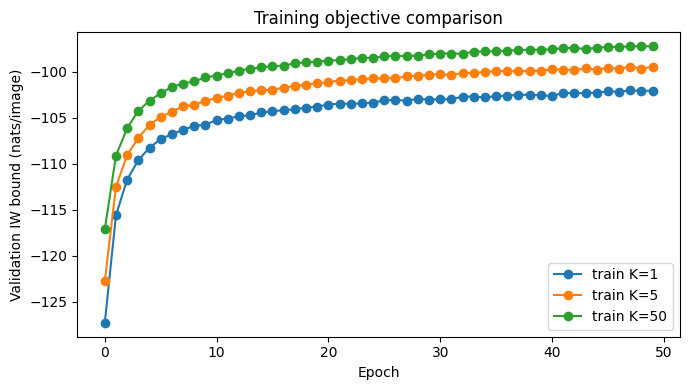

In [5]:
plt.figure(figsize=(7, 4))
for train_K in train_K_values:
    plt.plot(histories[train_K]['validation'], marker='o', label=f'train K={train_K}')
plt.xlabel('Epoch'); plt.ylabel('Validation IW bound (nats/image)')
plt.title('Training objective comparison')
plt.legend(); plt.tight_layout(); plt.show()

## Estimate validation bounds with different K

Evaluate both trained models using the same K values. These are Monte Carlo estimates of the bound: larger evaluation K is expected to tighten the bound in expectation, but individual estimates have sampling noise. Each estimate costs more as K grows. The training curves above use the training K, so compare those as optimization traces, not as identical objectives.

Model trained with K=1: eval K=1: -102.06, eval K=5: -99.62, eval K=50: -98.17
Model trained with K=5: eval K=1: -103.80, eval K=5: -99.46, eval K=50: -97.32
Model trained with K=50: eval K=1: -108.72, eval K=5: -100.78, eval K=50: -97.21


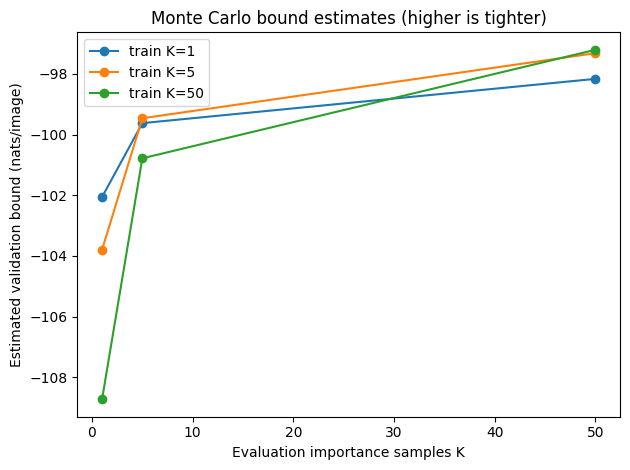

In [6]:
@torch.no_grad()
def estimate_bound(model, loader, K):
    model.eval()
    total = 0.0
    for images, _ in loader:
        total += iwae_bound(model, images.to(device), K).item() * images.size(0)
    return total / len(loader.dataset)

eval_K_values = [1, 5, 50]
evaluation = {}
for train_K, model in models.items():
    evaluation[train_K] = [estimate_bound(model, test_loader, K) for K in eval_K_values]
    print(f'Model trained with K={train_K}: ' + ', '.join(f'eval K={K}: {b:.2f}' for K, b in zip(eval_K_values, evaluation[train_K])))

for train_K in train_K_values:
    plt.plot(eval_K_values, evaluation[train_K], marker='o', label=f'train K={train_K}')
plt.xlabel('Evaluation importance samples K'); plt.ylabel('Estimated validation bound (nats/image)')
plt.title('Monte Carlo bound estimates (higher is tighter)')
plt.legend(); plt.tight_layout(); plt.show()

## Inspect reconstructions and prior samples

A tighter likelihood bound does not guarantee more visually appealing samples. Inspect reconstructions and unconditional prior samples separately from the bound estimates.

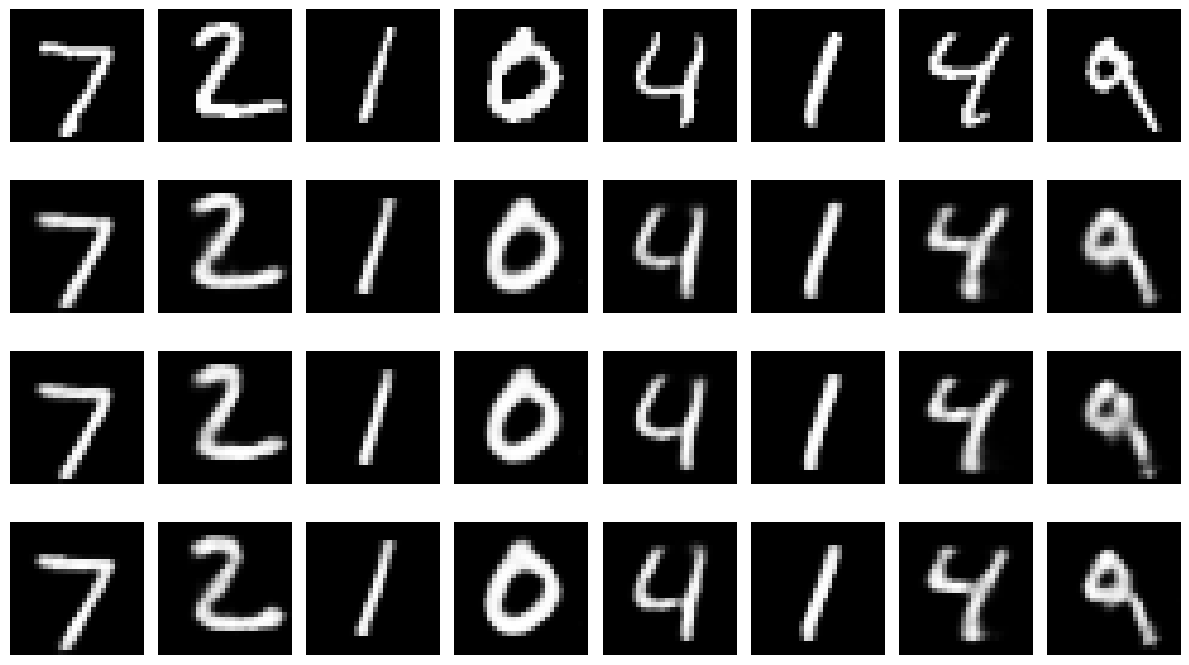

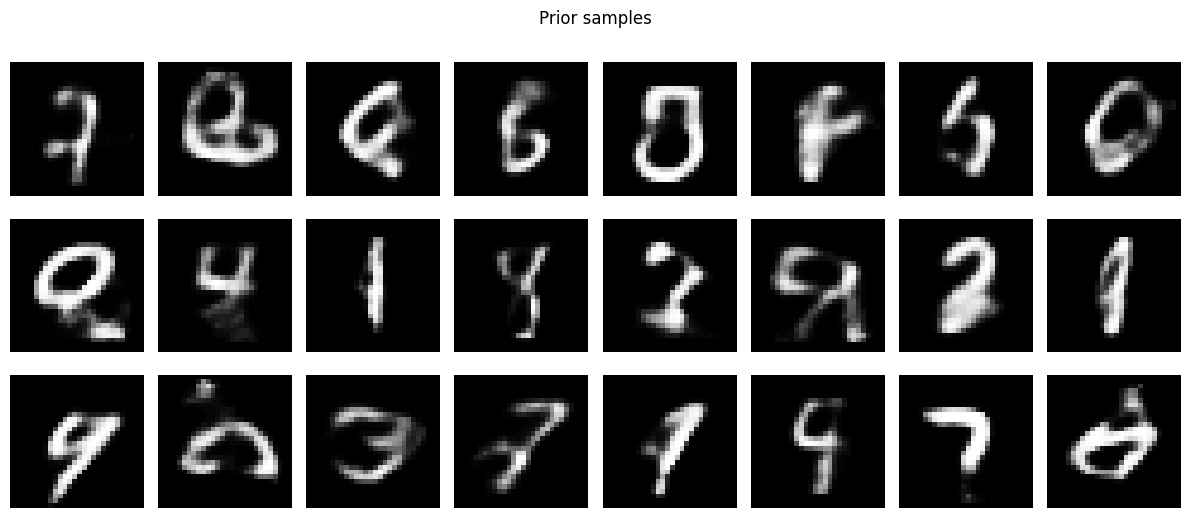

In [7]:
images, _ = next(iter(test_loader))
images = images[:8].to(device)
fig, axes = plt.subplots(len(train_K_values) + 1, 8, figsize=(12, 1.8 * (len(train_K_values) + 1)))
for j in range(8):
    axes[0, j].imshow(images[j, 0].cpu(), cmap='gray'); axes[0, j].axis('off')
axes[0, 0].set_ylabel('Input')
for row, train_K in enumerate(train_K_values, start=1):
    model = models[train_K].eval()
    with torch.no_grad(): mu, _ = model.encode(images); reconstruction = model.decode(mu)
    for j in range(8):
        axes[row, j].imshow(reconstruction[j, 0].cpu(), cmap='gray'); axes[row, j].axis('off')
    axes[row, 0].set_ylabel(f'train K={train_K}')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(train_K_values), 8, figsize=(12, 1.8 * len(train_K_values)))
for row, train_K in enumerate(train_K_values):
    model = models[train_K].eval()
    z = torch.randn(8, model.latent_dim, device=device)
    with torch.no_grad(): samples = model.decode(z).cpu()
    for j in range(8):
        axes[row, j].imshow(samples[j, 0], cmap='gray'); axes[row, j].axis('off')
    axes[row, 0].set_ylabel(f'train K={train_K}')
plt.suptitle('Prior samples')
plt.tight_layout(); plt.show()

## Engineering notes and takeaways

- `K=1` recovers the standard VAE ELBO estimator; increasing K tightens the expected bound.
- The log-mean-exp formulation is essential; do not replace it with a mean of log weights.
- More samples increase encoder/decoder computation and memory use. Importance weights can also become dominated by a few samples.
- A tighter bound does not guarantee an exact posterior, better downstream representations, better looking samples, or the elimination of posterior collapse. Monitor latent use and optimization stability.
- Choose K empirically, considering compute, validation bound estimates, and sample quality. Larger K can make inference-network gradient optimization harder; alternative estimators such as DReG were proposed to address this issue.
- IWAE is useful for likelihood-focused latent variable modeling and research comparisons. It is distinct from CVAE conditioning and Beta-VAE KL reweighting.

The foundational paper is Burda, Grosse, and Salakhutdinov (2015), [Importance Weighted Autoencoders](https://arxiv.org/abs/1509.00519).
